# LAB | Intro to Machine Learning

**Load the data**

In this challenge, we will be working with Spaceship Titanic data. The data can be found here:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv

Metadata

https://github.com/data-bootcamp-v4/data/blob/main/spaceship_titanic.md

In [17]:
#import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

SEED=1

In [2]:
spaceship = pd.read_csv("https://raw.githubusercontent.com/data-bootcamp-v4/data/main/spaceship_titanic.csv")
spaceship.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


**Check the shape of your data**

In [3]:
spaceship.shape

(8693, 14)

**Check for data types**

In [4]:
spaceship.dtypes

PassengerId      object
HomePlanet       object
CryoSleep        object
Cabin            object
Destination      object
Age             float64
VIP              object
RoomService     float64
FoodCourt       float64
ShoppingMall    float64
Spa             float64
VRDeck          float64
Name             object
Transported        bool
dtype: object

**Check for missing values**

In [5]:
spaceship.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

There are multiple strategies to handle missing data

- Removing all rows or all columns containing missing data.
- Filling all missing values with a value (mean in continouos or mode in categorical for example).
- Filling all missing values with an algorithm.

For this exercise, because we have such low amount of null values, we will drop rows containing any missing value. 

In [6]:
spaceship = spaceship.dropna()

In [7]:
spaceship.isnull().sum()

PassengerId     0
HomePlanet      0
CryoSleep       0
Cabin           0
Destination     0
Age             0
VIP             0
RoomService     0
FoodCourt       0
ShoppingMall    0
Spa             0
VRDeck          0
Name            0
Transported     0
dtype: int64

**KNN**

K Nearest Neighbors is a distance based algorithm, and requeries all **input data to be numerical.**

Let's only select numerical columns as our features.

In [8]:
spaceship.select_dtypes(include='number').columns

Index(['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck'], dtype='object')

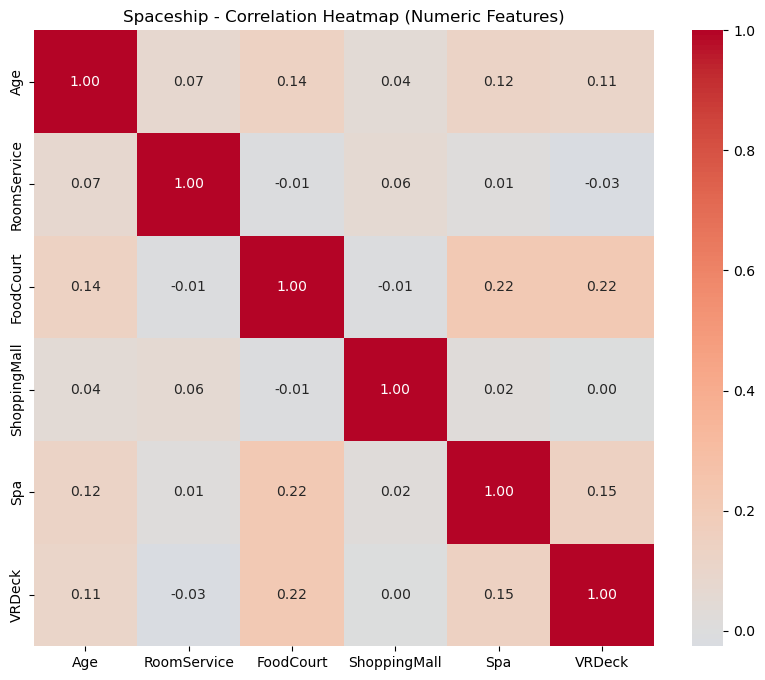

In [12]:
# Feature Selection: correlation heatmap
# Before selecting features, let's check how all 8 original columns correlate
# with each other and with the target, using a Pearson correlation heatmap.

num_cols = spaceship.select_dtypes(include='number')
full_corr = num_cols.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(full_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Spaceship - Correlation Heatmap (Numeric Features)')
plt.show()

And also lets define our target.

In [13]:
features = spaceship [['Age', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']]
target = spaceship["Transported"]

**Train Test Split**

Now that we have split the data into **features** and **target** variables and imported the **train_test_split** function, split X and y into X_train, X_test, y_train, and y_test. 80% of the data should be in the training set and 20% in the test set.

In [16]:
# Use stratify, beacuse the y is a categorical target

X_train, X_test, y_train, y_test = train_test_split(
    features, target,
    test_size=0.2,
    random_state=SEED,
    stratify=target)

print(X_train.shape)
print(X_test.shape)

(5284, 6)
(1322, 6)


In [18]:
# FEATURE ENGENEERING: Feature Scaling
# Standardize with MinMaxScaler

scaler = MinMaxScaler()
scaler.set_output(transform="pandas")  # mantém nomes das colunas
# set_output(transform="pandas") makes the scaler return a DataFrame (keeps the real column names and index)

# Fit ONLY on X_train --> avoids leaking any information from the test set into the scaling parameters
X_train_scaled_df = scaler.fit_transform(X_train)

# Then apply that same transformation to X_test
X_test_scaled_df = scaler.transform(X_test)

# BEFORE: original scale
print('BEFORE scaling (X_train):')
print(X_train.describe().loc[['mean', 'std']].round(4))
print()

# AFTER: standardized scale
print('AFTER scaling (X_train):')
print(X_train_scaled_df.describe().loc[['mean', 'std']].round(4))

BEFORE scaling (X_train):
          Age  RoomService  FoodCourt  ShoppingMall        Spa     VRDeck
mean  28.9080     222.4037   475.6171      176.9722   308.2684   296.1684
std   14.4869     639.4044  1620.5749      592.2009  1108.4575  1118.2181

AFTER scaling (X_train):
         Age  RoomService  FoodCourt  ShoppingMall     Spa  VRDeck
mean  0.3659       0.0224     0.0160        0.0144  0.0186  0.0146
std   0.1834       0.0645     0.0544        0.0483  0.0668  0.0550


**Model Selection**

In this exercise we will be using **KNN** as our predictive model.

You need to choose between **Classificator** or **Regressor**. Take into consideration target variable to decide.

Initialize a KNN instance without setting any hyperparameter.

In [19]:
#Create the KNN Classifier Model (Classifier because we have a categorical target)

knn = KNeighborsClassifier(n_neighbors=5)

In [20]:
#Train the model

knn.fit(X_train_scaled_df, y_train);
print("Model is trained!")

Model is trained!


Fit the model to your data.

In [21]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled_df, y_train)

y_pred_train = knn.predict(X_train_scaled_df)
y_pred_test = knn.predict(X_test_scaled_df)

print("Accuracy (Train):", accuracy_score(y_train, y_pred_train))
print("Accuracy (Test):", accuracy_score(y_test, y_pred_test))

print(classification_report(y_test, y_pred_test))

Accuracy (Train): 0.799772899318698
Accuracy (Test): 0.764750378214826
              precision    recall  f1-score   support

       False       0.79      0.72      0.75       656
        True       0.75      0.81      0.78       666

    accuracy                           0.76      1322
   macro avg       0.77      0.76      0.76      1322
weighted avg       0.77      0.76      0.76      1322



Evaluate your model.

In [13]:
# On the previous lab, when using all features, including categorical variables transformed into dummies, the KNN model achieved higher performance 
# (Train: 0.8319, Test: 0.7670).

# This improvement occurs because categorical variables contain meaningful information about passenger behavior 
# (e.g., HomePlanet, Destination, CryoSleep, VIP), which increases the model’s predictive power.

# In the current exercise, the model was trained only on numerical features, resulting in slightly lower performance (Train: 0.7997, Test: 0.7647).
# This reduction is expected and intentional, since the goal of the exercise is to practice KNN using strictly numerical inputs, without encoding 
# categorical variables.

# The small difference in test accuracy shows that the model still generalizes well, even with fewer features.
# Overall, the comparison highlights how feature richness (including encoded categorical variables) can significantly improve KNN performance, 
# while also demonstrating the importance of following the specific constraints of each exercise.

**Congratulations, you have just developed your first Machine Learning model!**